In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
import os
import json
import zipfile

from pathlib import Path
from IPython.display import display
from google.colab import files

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
uploaded = files.upload()

csv_files = [
    name for name in uploaded
    if name.lower().endswith(".csv")
]

if len(csv_files) != 1:
    raise ValueError("Upload exactly one CSV dataset.")

file_path = csv_files[0]

print("Dataset:", file_path)

Saving ev_charging_stations_india_cleaned.csv to ev_charging_stations_india_cleaned.csv
Dataset: ev_charging_stations_india_cleaned.csv


In [5]:
df = pd.read_csv(file_path)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Rows: 1000
Columns: 10


,station_id,station_name,city,state,country,latitude,longitude,charging_points,status,operator
0,479727,Nikol EV Charging station,Pune,Unknown,India,18.717182,74.182921,1,Operational,Unknown
1,479445,Blaze Fast Charger For 2 Ev Wheeler,Lb Nagar,Telangana,India,17.340476,78.545395,1,Operational,Bolt.Earth (IN)
2,479438,Tata Power Charging Station,Unknown,Odisha,India,22.286961,86.790983,1,Operational,Unknown
3,479437,Hindustan Petroleum Corporation Limited Chargi...,Unknown,Odisha,India,22.449744,86.594944,2,Operational,Unknown
4,479436,Hindustan Petroleum Corporation Limited,Unknown,Odisha,India,22.449858,86.595041,1,Operational,Unknown


In [6]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())

Column names:
['station_id', 'station_name', 'city', 'state', 'country', 'latitude', 'longitude', 'charging_points', 'status', 'operator']

Data types:


,Data Type
station_id,int64
station_name,object
city,object
state,object
country,object
latitude,float64
longitude,float64
charging_points,int64
status,object
operator,object



Missing values:


,Missing Values
station_id,0
station_name,0
city,0
state,0
country,0
latitude,0
longitude,0
charging_points,0
status,0
operator,0



Duplicate rows: 0


In [7]:
df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print(df.columns.tolist())

['station_id', 'station_name', 'city', 'state', 'country', 'latitude', 'longitude', 'charging_points', 'status', 'operator']


In [8]:
latitude_options = [
    "latitude", "lat", "station_latitude", "location_latitude"
]

longitude_options = [
    "longitude", "lon", "lng", "long",
    "station_longitude", "location_longitude"
]

latitude_col = next(
    (c for c in latitude_options if c in df.columns),
    None
)

longitude_col = next(
    (c for c in longitude_options if c in df.columns),
    None
)

if latitude_col is None or longitude_col is None:
    raise ValueError(
        "Latitude/longitude columns were not found. "
        f"Available columns: {df.columns.tolist()}"
    )

print("Latitude:", latitude_col)
print("Longitude:", longitude_col)

Latitude: latitude
Longitude: longitude


In [9]:
df[latitude_col] = pd.to_numeric(
    df[latitude_col], errors="coerce"
)

df[longitude_col] = pd.to_numeric(
    df[longitude_col], errors="coerce"
)

df = df.drop_duplicates().copy()

valid_coordinates = (
    df[latitude_col].between(-90, 90)
    & df[longitude_col].between(-180, 180)
)

stations = df.loc[valid_coordinates].copy()

stations = stations.rename(
    columns={
        latitude_col: "latitude",
        longitude_col: "longitude"
    }
).reset_index(drop=True)

if stations.empty:
    raise ValueError("No valid geographic records remain.")

print("Valid records:", len(stations))

display(stations.head())

Valid records: 1000


,station_id,station_name,city,state,country,latitude,longitude,charging_points,status,operator
0,479727,Nikol EV Charging station,Pune,Unknown,India,18.717182,74.182921,1,Operational,Unknown
1,479445,Blaze Fast Charger For 2 Ev Wheeler,Lb Nagar,Telangana,India,17.340476,78.545395,1,Operational,Bolt.Earth (IN)
2,479438,Tata Power Charging Station,Unknown,Odisha,India,22.286961,86.790983,1,Operational,Unknown
3,479437,Hindustan Petroleum Corporation Limited Chargi...,Unknown,Odisha,India,22.449744,86.594944,2,Operational,Unknown
4,479436,Hindustan Petroleum Corporation Limited,Unknown,Odisha,India,22.449858,86.595041,1,Operational,Unknown


In [10]:
print("EXISTING EV CHARGING STATION SUMMARY")
print("-" * 40)

print("Total station records:", len(stations))

print(
    "Unique coordinates:",
    stations[["latitude", "longitude"]].drop_duplicates().shape[0]
)

print("Latitude range:",
      stations["latitude"].min(),
      "to",
      stations["latitude"].max())

print("Longitude range:",
      stations["longitude"].min(),
      "to",
      stations["longitude"].max())

EXISTING EV CHARGING STATION SUMMARY
----------------------------------------
Total station records: 1000
Unique coordinates: 912
Latitude range: 8.194502907 to 32.21450539
Longitude range: 72.90804617 to 91.8512


In [11]:
status_options = [
    "status", "station_status", "operational_status"
]

status_col = next(
    (c for c in status_options if c in stations.columns),
    None
)

if status_col:
    display(
        stations[status_col]
        .value_counts(dropna=False)
        .to_frame("Count")
    )
else:
    print("Station status is not available in the dataset.")

,Count
status,
Operational,969
Not Operational,15
Temporarily Unavailable,10
Planned For Future Date,5
Partly Operational (Mixed),1


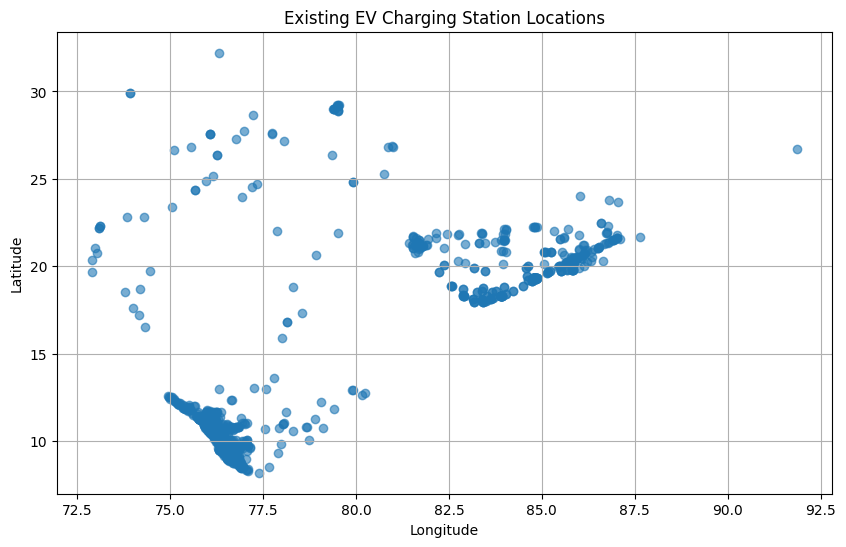

In [12]:
plt.figure(figsize=(10, 6))

plt.scatter(
    stations["longitude"],
    stations["latitude"],
    alpha=0.6
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Existing EV Charging Station Locations")
plt.grid(True)
plt.show()

In [13]:
city_options = ["city", "city_name", "town"]
state_options = ["state", "state_name", "province"]

city_col = next(
    (c for c in city_options if c in stations.columns),
    None
)

state_col = next(
    (c for c in state_options if c in stations.columns),
    None
)

if city_col:
    print("Station records by city:")
    display(
        stations[city_col]
        .value_counts()
        .head(15)
        .to_frame("Station Records")
    )

if state_col:
    print("Station records by state:")
    display(
        stations[state_col]
        .value_counts()
        .head(15)
        .to_frame("Station Records")
    )

Station records by city:


,Station Records
city,
Unknown,382
Kozhikode,20
Thrissur,19
Thiruvananthapuram,13
Nedumbassery,8
Alappuzha,6
Kannur,6
Kottayam,6
Haldwani,6


Station records by state:


,Station Records
state,
Kerala,514
Odisha,370
Tamil Nadu,26
Uttarakhand,12
Rajasthan,10
Gujarat,7
Uttar Pradesh,6
Unknown,6
Karnataka,6


In [14]:
GRID_SIZE = 0.1

stations["grid_lat"] = (
    np.floor(stations["latitude"] / GRID_SIZE) * GRID_SIZE
)

stations["grid_lon"] = (
    np.floor(stations["longitude"] / GRID_SIZE) * GRID_SIZE
)

grid_summary = (
    stations.groupby(["grid_lat", "grid_lon"])
    .size()
    .reset_index(name="existing_station_records")
)

grid_summary["center_latitude"] = (
    grid_summary["grid_lat"] + GRID_SIZE / 2
)

grid_summary["center_longitude"] = (
    grid_summary["grid_lon"] + GRID_SIZE / 2
)

print("Grid cells created:", len(grid_summary))

display(grid_summary.head())

Grid cells created: 404


,grid_lat,grid_lon,existing_station_records,center_latitude,center_longitude
0,8.1,77.3,1,8.15,77.35
1,8.3,77.0,4,8.35,77.05
2,8.4,76.9,7,8.45,76.95
3,8.5,76.8,7,8.55,76.85
4,8.5,76.9,7,8.55,76.95


In [15]:
candidate_areas = grid_summary.copy()

candidate_areas = candidate_areas.sort_values(
    "existing_station_records",
    ascending=True
).reset_index(drop=True)

candidate_areas["candidate_rank"] = (
    np.arange(1, len(candidate_areas) + 1)
)

candidate_areas["coverage_priority"] = (
    1 / (candidate_areas["existing_station_records"] + 1)
)

print("Preliminary candidate locations identified.")

display(candidate_areas.head(10))

Preliminary candidate locations identified.


,grid_lat,grid_lon,existing_station_records,center_latitude,center_longitude,candidate_rank,coverage_priority
0,17.3,78.5,1,17.35,78.55,1,0.5
1,19.9,85.8,1,19.95,85.85,2,0.5
2,19.8,85.6,1,19.85,85.65,3,0.5
3,19.7,74.4,1,19.75,74.45,4,0.5
4,19.6,72.9,1,19.65,72.95,5,0.5
5,18.8,78.3,1,18.85,78.35,6,0.5
6,18.7,74.1,1,18.75,74.15,7,0.5
7,18.5,73.8,1,18.55,73.85,8,0.5
8,17.6,74.0,1,17.65,74.05,9,0.5
9,19.9,85.9,1,19.95,85.95,10,0.5


In [16]:
top_candidates = candidate_areas.head(20).copy()

top_candidates["candidate_id"] = [
    f"CAND-{i:03d}"
    for i in range(1, len(top_candidates) + 1)
]

top_candidates = top_candidates[
    [
        "candidate_id",
        "candidate_rank",
        "center_latitude",
        "center_longitude",
        "existing_station_records",
        "coverage_priority"
    ]
]

display(top_candidates)

,candidate_id,candidate_rank,center_latitude,center_longitude,existing_station_records,coverage_priority
0,CAND-001,1,17.35,78.55,1,0.5
1,CAND-002,2,19.95,85.85,1,0.5
2,CAND-003,3,19.85,85.65,1,0.5
3,CAND-004,4,19.75,74.45,1,0.5
4,CAND-005,5,19.65,72.95,1,0.5
5,CAND-006,6,18.85,78.35,1,0.5
6,CAND-007,7,18.75,74.15,1,0.5
7,CAND-008,8,18.55,73.85,1,0.5
8,CAND-009,9,17.65,74.05,1,0.5
9,CAND-010,10,19.95,85.95,1,0.5


In [17]:
def haversine_km(lat1, lon1, lat2, lon2):
    earth_radius = 6371.0

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    return 2 * earth_radius * np.arcsin(
        np.sqrt(np.clip(a, 0, 1))
    )


candidate_latitudes = top_candidates[
    "center_latitude"
].to_numpy()

candidate_longitudes = top_candidates[
    "center_longitude"
].to_numpy()

station_latitudes = stations["latitude"].to_numpy()
station_longitudes = stations["longitude"].to_numpy()

nearest_distances = []

for lat, lon in zip(
    candidate_latitudes,
    candidate_longitudes
):
    distances = haversine_km(
        lat,
        lon,
        station_latitudes,
        station_longitudes
    )

    nearest_distances.append(float(np.min(distances)))

top_candidates["nearest_station_km"] = nearest_distances

display(
    top_candidates.sort_values(
        "nearest_station_km",
        ascending=False
    )
)

,candidate_id,candidate_rank,center_latitude,center_longitude,existing_station_records,coverage_priority,nearest_station_km
7,CAND-008,8,18.55,73.85,1,0.5,7.073979
13,CAND-014,14,13.65,77.75,1,0.5,6.314000
9,CAND-010,10,19.95,85.95,1,0.5,5.780260
12,CAND-013,13,15.85,78.05,1,0.5,5.409629
4,CAND-005,5,19.65,72.95,1,0.5,5.380614
6,CAND-007,7,18.75,74.15,1,0.5,5.033362
1,CAND-002,2,19.95,85.85,1,0.5,4.337909
10,CAND-011,11,17.25,74.15,1,0.5,4.289025
8,CAND-009,9,17.65,74.05,1,0.5,4.247148
5,CAND-006,6,18.85,78.35,1,0.5,4.234534


In [18]:
top_candidates["distance_score"] = (
    top_candidates["nearest_station_km"]
    / max(
        top_candidates["nearest_station_km"].max(),
        1e-9
    )
)

top_candidates["coverage_score"] = (
    top_candidates["coverage_priority"]
    / max(
        top_candidates["coverage_priority"].max(),
        1e-9
    )
)

top_candidates["priority_score"] = (
    0.7 * top_candidates["distance_score"]
    + 0.3 * top_candidates["coverage_score"]
)

top_candidates = top_candidates.sort_values(
    "priority_score",
    ascending=False
).reset_index(drop=True)

top_candidates["final_rank"] = (
    np.arange(1, len(top_candidates) + 1)
)

display(top_candidates)

,candidate_id,candidate_rank,center_latitude,center_longitude,existing_station_records,coverage_priority,nearest_station_km,distance_score,coverage_score,priority_score,final_rank
0,CAND-008,8,18.55,73.85,1,0.5,7.073979,1.000000,1.0,1.000000,1
1,CAND-014,14,13.65,77.75,1,0.5,6.314000,0.892567,1.0,0.924797,2
2,CAND-010,10,19.95,85.95,1,0.5,5.780260,0.817116,1.0,0.871981,3
3,CAND-013,13,15.85,78.05,1,0.5,5.409629,0.764722,1.0,0.835306,4
4,CAND-005,5,19.65,72.95,1,0.5,5.380614,0.760621,1.0,0.832434,5
5,CAND-007,7,18.75,74.15,1,0.5,5.033362,0.711532,1.0,0.798072,6
6,CAND-002,2,19.95,85.85,1,0.5,4.337909,0.613221,1.0,0.729254,7
7,CAND-011,11,17.25,74.15,1,0.5,4.289025,0.606310,1.0,0.724417,8
8,CAND-009,9,17.65,74.05,1,0.5,4.247148,0.600390,1.0,0.720273,9
9,CAND-006,6,18.85,78.35,1,0.5,4.234534,0.598607,1.0,0.719025,10


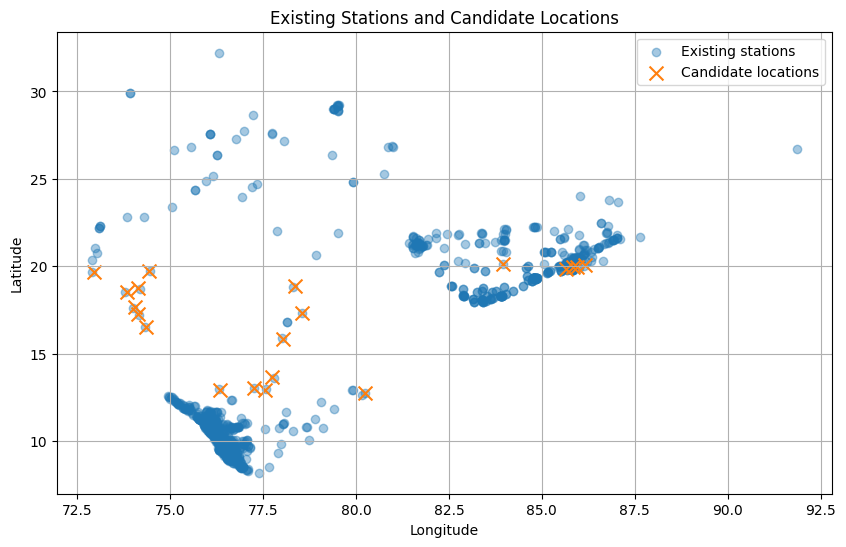

In [19]:
plt.figure(figsize=(10, 6))

plt.scatter(
    stations["longitude"],
    stations["latitude"],
    label="Existing stations",
    alpha=0.4
)

plt.scatter(
    top_candidates["center_longitude"],
    top_candidates["center_latitude"],
    label="Candidate locations",
    marker="x",
    s=100
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Existing Stations and Candidate Locations")
plt.legend()
plt.grid(True)
plt.show()

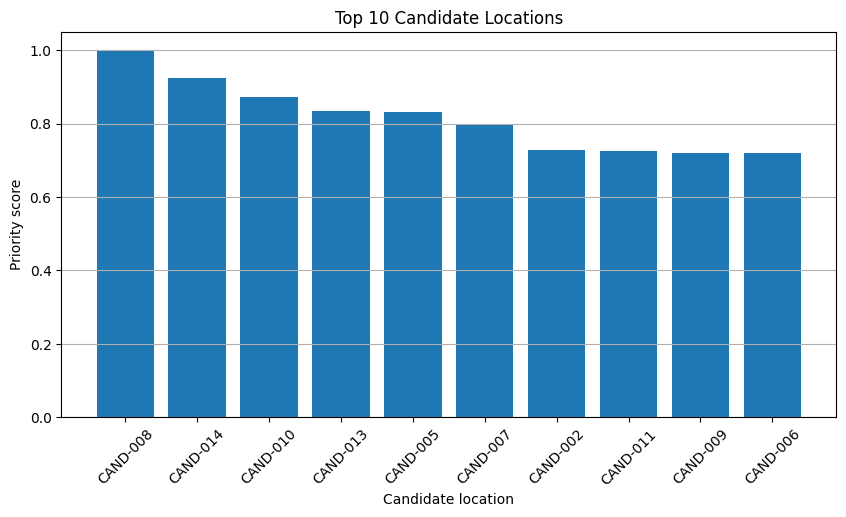

,candidate_id,candidate_rank,center_latitude,center_longitude,existing_station_records,coverage_priority,nearest_station_km,distance_score,coverage_score,priority_score,final_rank
0,CAND-008,8,18.55,73.85,1,0.5,7.073979,1.000000,1.0,1.000000,1
1,CAND-014,14,13.65,77.75,1,0.5,6.314000,0.892567,1.0,0.924797,2
2,CAND-010,10,19.95,85.95,1,0.5,5.780260,0.817116,1.0,0.871981,3
3,CAND-013,13,15.85,78.05,1,0.5,5.409629,0.764722,1.0,0.835306,4
4,CAND-005,5,19.65,72.95,1,0.5,5.380614,0.760621,1.0,0.832434,5
5,CAND-007,7,18.75,74.15,1,0.5,5.033362,0.711532,1.0,0.798072,6
6,CAND-002,2,19.95,85.85,1,0.5,4.337909,0.613221,1.0,0.729254,7
7,CAND-011,11,17.25,74.15,1,0.5,4.289025,0.606310,1.0,0.724417,8
8,CAND-009,9,17.65,74.05,1,0.5,4.247148,0.600390,1.0,0.720273,9
9,CAND-006,6,18.85,78.35,1,0.5,4.234534,0.598607,1.0,0.719025,10


In [20]:
top_10 = top_candidates.head(10).copy()

plt.figure(figsize=(10, 5))

plt.bar(
    top_10["candidate_id"],
    top_10["priority_score"]
)

plt.xlabel("Candidate location")
plt.ylabel("Priority score")
plt.title("Top 10 Candidate Locations")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.show()

display(top_10)

In [21]:
COST_PER_STATION = 500000

BUDGETS = {
    "Low Budget": 2500000,
    "Medium Budget": 5000000,
    "High Budget": 10000000
}

print("Assumed cost per new station: ₹", COST_PER_STATION)

display(
    pd.DataFrame(
        [
            {"Budget Scenario": name, "Budget (₹)": amount}
            for name, amount in BUDGETS.items()
        ]
    )
)

Assumed cost per new station: ₹ 500000


,Budget Scenario,Budget (₹)
0,Low Budget,2500000
1,Medium Budget,5000000
2,High Budget,10000000


In [22]:
budget_results = []

ranked_candidates = top_candidates.sort_values(
    "priority_score",
    ascending=False
).reset_index(drop=True)

for scenario, budget in BUDGETS.items():
    number_affordable = budget // COST_PER_STATION

    selected = ranked_candidates.head(
        int(number_affordable)
    )

    budget_results.append(
        {
            "Scenario": scenario,
            "Budget (₹)": budget,
            "Assumed Cost per Station (₹)": COST_PER_STATION,
            "Stations Affordable": int(number_affordable),
            "Candidates Available": len(ranked_candidates),
            "Candidates Selected": len(selected),
            "Total Assumed Cost (₹)": (
                len(selected) * COST_PER_STATION
            ),
            "Average Priority Score": (
                selected["priority_score"].mean()
                if len(selected) > 0
                else 0
            )
        }
    )

budget_comparison = pd.DataFrame(budget_results)

display(budget_comparison)

,Scenario,Budget (₹),Assumed Cost per Station (₹),Stations Affordable,Candidates Available,Candidates Selected,Total Assumed Cost (₹),Average Priority Score
0,Low Budget,2500000,500000,5,20,5,2500000,0.892904
1,Medium Budget,5000000,500000,10,20,10,5000000,0.815556
2,High Budget,10000000,500000,20,20,20,10000000,0.677363


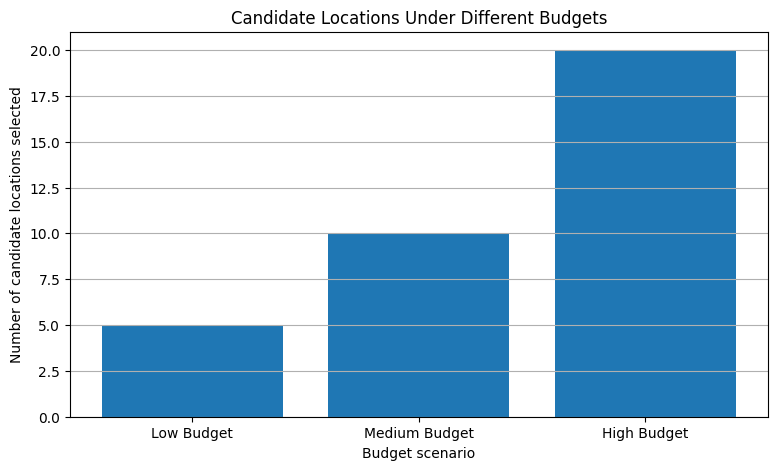

In [23]:
plt.figure(figsize=(9, 5))

plt.bar(
    budget_comparison["Scenario"],
    budget_comparison["Candidates Selected"]
)

plt.xlabel("Budget scenario")
plt.ylabel("Number of candidate locations selected")
plt.title("Candidate Locations Under Different Budgets")
plt.grid(axis="y")
plt.show()

In [24]:
coverage_summary = pd.DataFrame(
    {
        "Metric": [
            "Existing station records",
            "Unique existing coordinates",
            "Geographic grid cells",
            "Preliminary candidate locations",
            "Candidates at least 5 km from an existing station",
            "Candidates at least 10 km from an existing station"
        ],
        "Value": [
            len(stations),
            stations[["latitude", "longitude"]]
            .drop_duplicates().shape[0],
            len(grid_summary),
            len(top_candidates),
            int((top_candidates["nearest_station_km"] >= 5).sum()),
            int((top_candidates["nearest_station_km"] >= 10).sum())
        ]
    }
)

display(coverage_summary)

,Metric,Value
0,Existing station records,1000
1,Unique existing coordinates,912
2,Geographic grid cells,404
3,Preliminary candidate locations,20
4,Candidates at least 5 km from an existing station,6
5,Candidates at least 10 km from an existing sta...,0


In [25]:
import folium

center_latitude = stations["latitude"].mean()
center_longitude = stations["longitude"].mean()

station_map = folium.Map(
    location=[center_latitude, center_longitude],
    zoom_start=5
)

for _, row in stations.iterrows():
    folium.CircleMarker(
        location=[row["latitude"], row["longitude"]],
        radius=3,
        popup="Existing station",
        fill=True
    ).add_to(station_map)

for _, row in top_candidates.head(10).iterrows():
    folium.Marker(
        location=[
            row["center_latitude"],
            row["center_longitude"]
        ],
        popup=(
            f"Candidate: {row['candidate_id']} | "
            f"Rank: {row['final_rank']} | "
            f"Nearest station: "
            f"{row['nearest_station_km']:.2f} km"
        ),
        icon=folium.Icon(color="red", icon="plus")
    ).add_to(station_map)

station_map

In [26]:
from IPython.display import HTML, display

dashboard_html = f"""
<div style="font-family:Arial;padding:20px;background:#f3f6fa;">
    <h1>EV Charging Station Placement Dashboard</h1>
    <p>Preliminary geographic analysis and budget planning</p>

    <div style="display:flex;gap:15px;flex-wrap:wrap;">
        <div style="background:white;padding:20px;border-radius:10px;">
            <h3>Existing Records</h3>
            <h2>{len(stations):,}</h2>
        </div>

        <div style="background:white;padding:20px;border-radius:10px;">
            <h3>Geographic Grid Cells</h3>
            <h2>{len(grid_summary):,}</h2>
        </div>

        <div style="background:white;padding:20px;border-radius:10px;">
            <h3>Candidate Locations</h3>
            <h2>{len(top_candidates):,}</h2>
        </div>

        <div style="background:white;padding:20px;border-radius:10px;">
            <h3>Low-Budget Scenario</h3>
            <h2>₹25 lakh</h2>
        </div>
    </div>

    <h2>Top Candidate Locations</h2>
    {top_candidates.head(10).to_html(index=False)}

    <h2>Budget Comparison</h2>
    {budget_comparison.to_html(index=False)}

    <p>
        Note: Candidate rankings are preliminary. Installation costs are
        assumptions, and the analysis does not establish actual demand,
        grid capacity, or commercial feasibility.
    </p>
</div>
"""

display(HTML(dashboard_html))

candidate_id,candidate_rank,center_latitude,center_longitude,existing_station_records,coverage_priority,nearest_station_km,distance_score,coverage_score,priority_score,final_rank
CAND-008,8,18.55,73.85,1,0.5,7.073979,1.000000,1.0,1.000000,1
CAND-014,14,13.65,77.75,1,0.5,6.314000,0.892567,1.0,0.924797,2
CAND-010,10,19.95,85.95,1,0.5,5.780260,0.817116,1.0,0.871981,3
CAND-013,13,15.85,78.05,1,0.5,5.409629,0.764722,1.0,0.835306,4
CAND-005,5,19.65,72.95,1,0.5,5.380614,0.760621,1.0,0.832434,5
CAND-007,7,18.75,74.15,1,0.5,5.033362,0.711532,1.0,0.798072,6
CAND-002,2,19.95,85.85,1,0.5,4.337909,0.613221,1.0,0.729254,7
CAND-011,11,17.25,74.15,1,0.5,4.289025,0.606310,1.0,0.724417,8
CAND-009,9,17.65,74.05,1,0.5,4.247148,0.600390,1.0,0.720273,9
CAND-006,6,18.85,78.35,1,0.5,4.234534,0.598607,1.0,0.719025,10


In [27]:
output_folder = Path("ev_project_outputs")
output_folder.mkdir(exist_ok=True)

stations.to_csv(
    output_folder / "cleaned_station_data.csv",
    index=False
)

grid_summary.to_csv(
    output_folder / "geographic_grid_summary.csv",
    index=False
)

top_candidates.to_csv(
    output_folder / "candidate_locations.csv",
    index=False
)

budget_comparison.to_csv(
    output_folder / "budget_comparison.csv",
    index=False
)

coverage_summary.to_csv(
    output_folder / "coverage_summary.csv",
    index=False
)

station_map.save(
    str(output_folder / "station_map.html")
)

print("Project outputs saved successfully.")
print("Output folder:", output_folder)

Project outputs saved successfully.
Output folder: ev_project_outputs


In [28]:
readme_text = """
# Optimal EV Charging Station Placement

## Project Overview
This project analyses existing electric vehicle charging station records
and identifies preliminary candidate areas for further investigation.

## Tools Used
- Python
- Pandas
- NumPy
- Matplotlib
- Folium
- Google Colab
- GitHub

## Main Features
- Data cleaning and validation
- Geographic station distribution analysis
- Preliminary candidate location ranking
- Straight-line distance analysis
- Illustrative budget scenario comparison
- Geographic map and planning dashboard

## Limitations
Candidate locations are preliminary geographic suggestions, not verified
installation sites. The dataset may not contain traffic demand, charging
sessions, electricity grid capacity, road-network distance, or real
installation costs. Budget calculations use explicitly stated assumptions.

## Outputs
- Cleaned station data
- Geographic grid summary
- Candidate locations
- Budget comparison
- Coverage summary
- Geographic map
"""

Path("README.md").write_text(
    readme_text.strip() + "\n",
    encoding="utf-8"
)

print("README.md created.")

README.md created.


In [29]:
requirements_text = """pandas
numpy
matplotlib
folium
"""

Path("requirements.txt").write_text(
    requirements_text,
    encoding="utf-8"
)

print("requirements.txt created.")

requirements.txt created.


In [30]:
zip_filename = "EV_Charging_Station_Placement_Project.zip"

with zipfile.ZipFile(
    zip_filename,
    "w",
    zipfile.ZIP_DEFLATED
) as zip_file:

    for path in Path("ev_project_outputs").rglob("*"):
        if path.is_file():
            zip_file.write(path)

    zip_file.write("README.md")
    zip_file.write("requirements.txt")

print("Project package created:", zip_filename)

Project package created: EV_Charging_Station_Placement_Project.zip


In [31]:
files.download("EV_Charging_Station_Placement_Project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>